In [1]:
import sys
!{sys.executable} -m pip install pydoe2 diversipy scikit-learn

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyDOE2
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures

sys.modules["pyDOE"] = pyDOE2
from doepy import build, read_write

read_write.write_csv(
    build.central_composite(
        read_write.read_variables_csv('VolTestFDOPA.csv'),
        face='ccf'
    ),
    filename='DOE_table.csv'
)

In [3]:
data = pd.read_csv('DOE_table-2.csv')

# Extract features and target variable
X = data[['Pre', 'Cu', 'Bu', 'Pyr']].values  # Replace with your feature columns
y = data['RCC'].values  # Replace with your target column

# Create polynomial features
poly = PolynomialFeatures(degree=2)  # Change the degree if needed
X_poly = poly.fit_transform(X)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_poly, y, test_size=0.2, random_state=42)

# Create and fit the model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

In [4]:
# Evaluate the model
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error: {mse}")
print(f"R^2 Score: {r2}")

Mean Squared Error: 10.797556635351407
R^2 Score: 0.9546765497326791


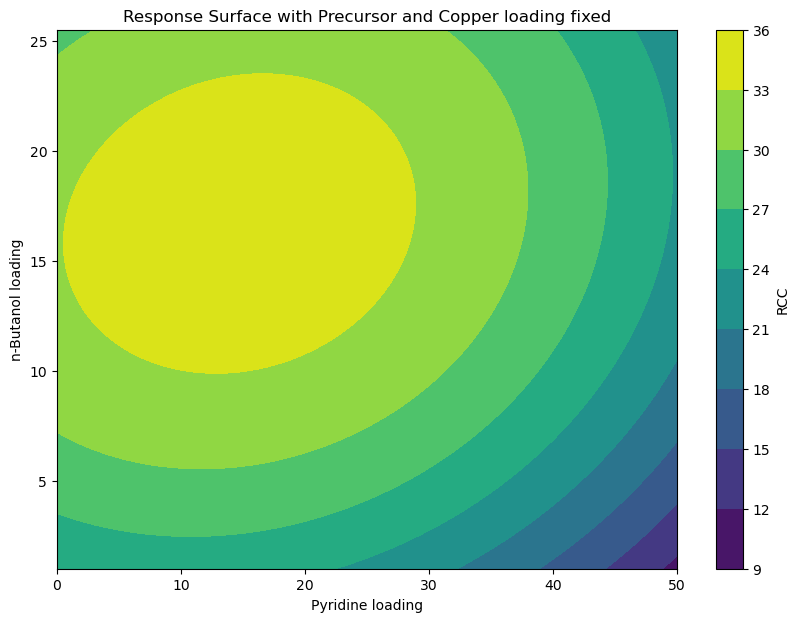

In [5]:
fixed_feature1 = 1.0
fixed_feature2 = 2.0

feature3_range = np.linspace(X[:, 2].min(), X[:, 2].max(), 100)
feature4_range = np.linspace(X[:, 3].min(), X[:, 3].max(), 100)
feature3_grid, feature4_grid = np.meshgrid(feature3_range, feature4_range)
grid_points = np.column_stack([
    np.full(feature3_grid.size, fixed_feature1),
    np.full(feature3_grid.size, fixed_feature2),
    feature3_grid.ravel(),
    feature4_grid.ravel()
])

grid_points_poly = poly.transform(grid_points)
y_grid = model.predict(grid_points_poly)
y_grid = y_grid.reshape(feature4_grid.shape)

plt.figure(figsize=(10, 7))
plt.contourf(feature3_grid, feature4_grid, y_grid, cmap='viridis')
plt.colorbar(label='RCC')
plt.xlabel('Pyridine loading')
plt.ylabel('n-Butanol loading')
plt.title('Response Surface with Precursor and Copper loading fixed')
plt.show()


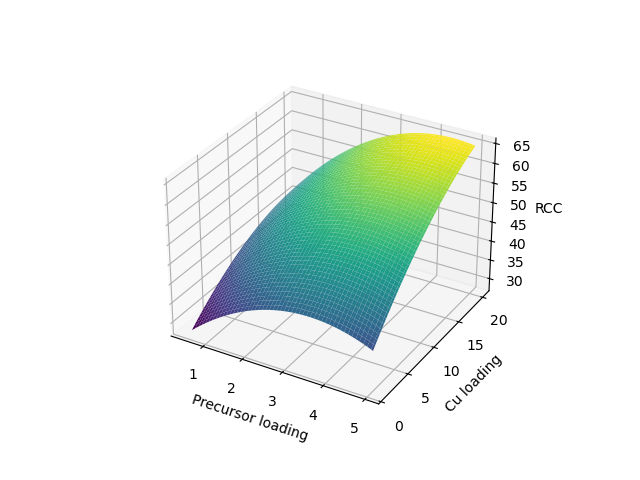

In [6]:
%config InlineBackend.print_figure_kwargs = {'bbox_inches': None}

x1_range = np.linspace(X[:, 0].min(), X[:, 0].max(), 100)
x2_range = np.linspace(X[:, 1].min(), X[:, 1].max(), 100)
x1_grid, x2_grid = np.meshgrid(x1_range, x2_range)

x3_const = np.full(x1_grid.ravel().shape, X[:, 2].mean())
x4_const = np.full(x1_grid.ravel().shape, X[:, 3].mean())

x_grid = np.column_stack([
    x1_grid.ravel(),
    x2_grid.ravel(),
    x3_const,
    x4_const
])

x_grid_poly = poly.transform(x_grid)
y_grid = model.predict(x_grid_poly)
y_grid = y_grid.reshape(x1_grid.shape)

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.plot_surface(x1_grid, x2_grid, y_grid, cmap='viridis')

ax.set_xlabel('Precursor loading')
ax.set_ylabel('Cu loading')
ax.set_zlabel('RCC')
plt.show()